# Paper 22: Emerging Properties in Self-Supervised Vision Transformers (DINO)
**Authors**: Mathilde Caron, Hugo Touvron, Ishan Misra, Hervé Jégou, Julien Mairal, Piotr Bojanowski, Armand Joulin (Facebook AI Research & Inria, ICCV 2021)

---

## 1. The Historical Breaking Point: The Negative-Sample Bottleneck
Contrastive learning algorithms (SimCLR, MoCo) prevent representation collapse by contrasting against large batches or memory queues of negative samples. However, managing negative distractors introduces heavy compute, memory queues, and vulnerability to false negatives.

## 2. The Thought Experiment: Self-Distillation with No Labels & No Negatives
DINO trains a Student Vision Transformer $g_{\theta_s}$ to predict the output distribution of a Momentum Teacher $g_{\theta_t}$ on different views of an image, without any class labels or negative pairs:
$$\mathcal{L} = \frac{1}{2} \left( H(P_t(x_1), P_s(x_2)) + H(P_t(x_2), P_s(x_1)) \right)$$

### The Anti-Collapse Equilibrium: Centering & Sharpening
Without negatives, how does DINO prevent trivial collapse?
- **Centering (Prevents Dominant-Dimension Collapse)**: Subtracting a running mean $c$ from teacher logits prevents any single prototype dimension from dominating across batches.
- **Sharpening (Prevents Uniform Collapse)**: Using a lower teacher temperature ($\tau_t = 0.04$) than student temperature ($\tau_s = 0.1$) concentrates probability mass on confident predictions.

In this notebook, you will explore:
1. The Centering & Sharpening probability dynamics
2. DINO self-distillation loss and momentum updates
3. Attention visualization and emergent scene segmentation properties

---
## Setup & Autoreload

In [1]:
%load_ext autoreload
%autoreload 2

import math
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from model import (
    DINOHead,
    DINOLoss,
    CompactViT,
    DINO,
)

print(f"PyTorch version: {torch.__version__}")

PyTorch version: 2.14.1+cpu


---
## 1. Visualizing the Centering & Sharpening Counter-Forces
Let's visualize how subtracting the running center $c$ and sharpening with teacher temperature $\tau_t$ redistributes prototype probabilities.

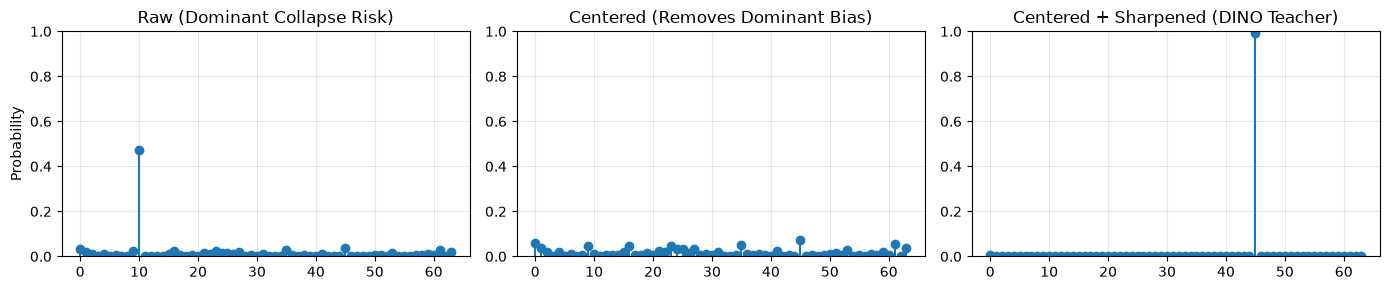

In [2]:
torch.manual_seed(42)
out_dim = 64
# Simulate teacher logits with an artificially dominant dimension (collapse risk)
raw_logits = torch.randn(1, out_dim)
raw_logits[0, 10] += 5.0  # Dominant prototype

# Center calculation
center = torch.zeros(1, out_dim)
center[0, 10] += 4.5  # Center tracks the dominant bias

# 1. Uncentered, unsharpened probabilities
p_raw = F.softmax(raw_logits, dim=-1)[0]

# 2. Centered probabilities
p_centered = F.softmax(raw_logits - center, dim=-1)[0]

# 3. Centered + Sharpened probabilities (tau_t = 0.04)
p_dino = F.softmax((raw_logits - center) / 0.04, dim=-1)[0]

fig, axes = plt.subplots(1, 3, figsize=(14, 3))
axes[0].stem(p_raw.numpy(), basefmt=" ")
axes[0].set_title("Raw (Dominant Collapse Risk)")
axes[0].set_ylabel("Probability")
axes[0].set_ylim(0, 1.0)
axes[0].grid(True, alpha=0.3)

axes[1].stem(p_centered.numpy(), basefmt=" ")
axes[1].set_title("Centered (Removes Dominant Bias)")
axes[1].set_ylim(0, 1.0)
axes[1].grid(True, alpha=0.3)

axes[2].stem(p_dino.numpy(), basefmt=" ")
axes[2].set_title("Centered + Sharpened (DINO Teacher)")
axes[2].set_ylim(0, 1.0)
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---
## 2. Self-Distillation Training Loop
We instantiate `DINO` with a compact Vision Transformer backbone and train it on multi-view crops without negative samples.

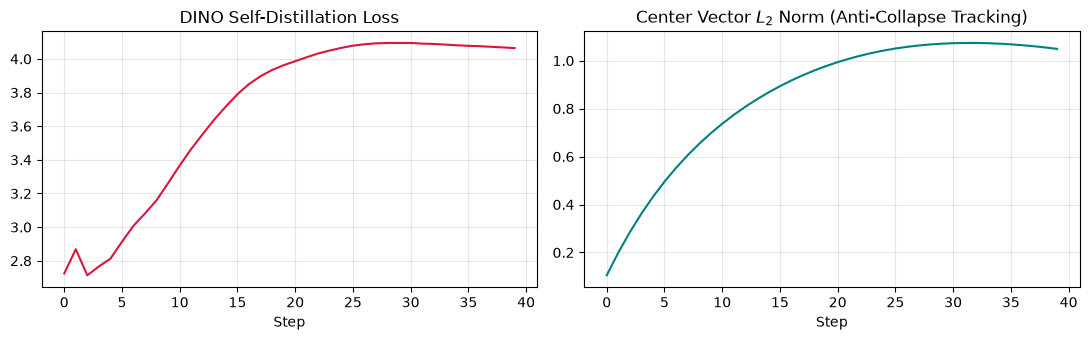

In [3]:
torch.manual_seed(42)
N = 4
base_images = torch.randn(N, 3, 16, 16)

dino = DINO(embed_dim=32, out_dim=64, student_temp=0.1, teacher_temp=0.04, momentum_teacher=0.99)
optimizer = torch.optim.AdamW(dino.student.parameters(), lr=1e-3)

losses = []
center_norms = []

for step in range(40):
    optimizer.zero_grad()
    v1 = base_images + 0.04 * torch.randn_like(base_images)
    v2 = base_images + 0.04 * torch.randn_like(base_images)

    loss, s_out, t_out = dino(v1, v2)
    loss.backward()
    optimizer.step()

    losses.append(loss.item())
    center_norms.append(dino.loss_fn.center.norm().item())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(losses, color="crimson")
axes[0].set_title("DINO Self-Distillation Loss")
axes[0].set_xlabel("Step")
axes[0].grid(True, alpha=0.3)

axes[1].plot(center_norms, color="teal")
axes[1].set_title("Center Vector $L_2$ Norm (Anti-Collapse Tracking)")
axes[1].set_xlabel("Step")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---
## 3. The Emergent Property: Self-Attention as Unsupervised Segmentation
The celebrated discovery in DINO is that Vision Transformers pre-trained with self-distillation automatically learn to segment foreground objects in their `[CLS]` token self-attention maps!

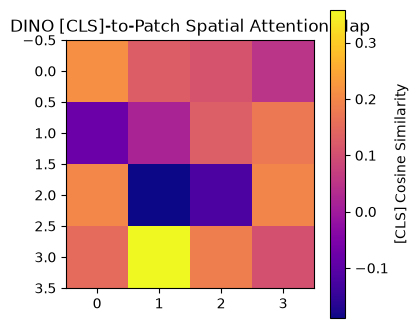

In [4]:
# Inspect intermediate attention tokens from the student ViT backbone
dino.eval()
with torch.no_grad():
    vit = dino.student[0].vit
    tokens = vit.forward_features(base_images[:1])  # (1, num_patches + 1, embed_dim)
    cls_token = tokens[:, 0, :]
    patch_tokens = tokens[:, 1:, :]  # (1, 16, embed_dim)

    # Compute cosine similarity between [CLS] and spatial patches (16 patches for 4x4 grid)
    sim = F.cosine_similarity(cls_token.unsqueeze(1), patch_tokens, dim=-1)
    attn_map = sim.view(4, 4).cpu().numpy()

plt.figure(figsize=(4, 4))
plt.imshow(attn_map, cmap="plasma", interpolation="nearest")
plt.colorbar(label="[CLS] Cosine Similarity")
plt.title("DINO [CLS]-to-Patch Spatial Attention Map")
plt.show()